In [33]:
import pandas as pd
import kagglehub
from kagglehub import KaggleDatasetAdapter

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

In [34]:
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "olaflundstrom/nordcauc-urban-mobility-intelligence",
    "traffic_flow_sensors.csv",
)
len(df)

200000

In [35]:
df.head()

,sensor_id,city,country,district,timestamp,date,hour,day_of_week,is_weekend,is_public_holiday,...,ev_count_15min,truck_count_15min,temperature_c,precipitation_mm,weather_condition,incident_type,ai_predicted_volume,ai_predicted_congestion,ai_model_version,data_quality_flag
0,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2023-01-02 04:00:00,2023-01-02,4,Monday,False,True,...,25,5,-2.9,4.0,light_rain,none,88,light,NordFlow-GNN,good
1,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2023-01-04 10:30:00,2023-01-04,10,Wednesday,False,False,...,23,2,-1.7,0.0,fog,none,74,light,NordFlow-GNN,good
2,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2023-01-05 17:00:00,2023-01-05,17,Thursday,False,False,...,70,7,-4.4,0.0,overcast,none,243,heavy,NordFlow-GNN,good
3,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2023-01-06 01:15:00,2023-01-06,1,Friday,False,False,...,6,1,-4.3,0.0,light_rain,none,22,free_flow,NordFlow-GNN,good
4,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2023-01-06 04:15:00,2023-01-06,4,Friday,False,False,...,7,1,-2.2,0.0,overcast,none,30,free_flow,NordFlow-GNN,good


In [36]:
df = df.sort_values(["sensor_id", "timestamp"])
df["future_congestion_level"] = df.groupby("sensor_id")["congestion_level"].shift(-1)
df["next_timestamp"] = df.groupby("sensor_id")["timestamp"].shift(-1)
df["duration_to_next"] = pd.to_datetime(df["next_timestamp"]) - pd.to_datetime(df["timestamp"])

df = df[df["duration_to_next"].dt.total_seconds() / 60 == 60]
df = df[df["data_quality_flag"] == "good"]
print(len(df), "rader")
df["future_congestion_level"].value_counts()

2070 rader


future_congestion_level
free_flow    976
moderate     377
light        371
heavy        346
Name: count, dtype: int64

In [44]:
y = df["future_congestion_level"]
X = df.drop(columns=[
    "future_congestion_level", "next_timestamp", "duration_to_next",
    "sensor_id", "country", "district", "timestamp", "date",
    "latitude", "longitude", "ev_count_15min",
    "ai_predicted_volume", "ai_predicted_congestion", "ai_model_version",
    "data_quality_flag",
])
X = pd.get_dummies(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

hur bra blir det om man alltid gissar att trängseln om en timme är samma som nu?

In [46]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Vanligaste klassen:", accuracy_score(y_test, dummy.predict(X_test)))

samma_som_nu = df.loc[X_test.index, "congestion_level"]
print("Samma som nu:     ", accuracy_score(y_test, samma_som_nu))

Vanligaste klassen: 0.47101449275362317
Samma som nu:      0.6231884057971014


In [47]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    print(name, ":", round(accuracy_score(y_test, m.predict(X_test)), 3))

Decision Tree : 0.826
Random Forest : 0.826
Logistic Regression : 0.676


In [48]:
for name, m in models.items():
    scores = cross_val_score(m, X, y, cv=5)
    print(name, ":", scores.mean().round(3), "±", scores.std().round(3))

Decision Tree : 0.787 ± 0.067
Random Forest : 0.807 ± 0.023
Logistic Regression : 0.551 ± 0.148


In [49]:
best = models["Random Forest"]   
print(classification_report(y_test, best.predict(X_test)))

              precision    recall  f1-score   support

   free_flow       0.87      0.95      0.91       195
       heavy       0.80      0.87      0.83        69
       light       0.73      0.49      0.59        74
    moderate       0.80      0.79      0.79        76

    accuracy                           0.83       414
   macro avg       0.80      0.77      0.78       414
weighted avg       0.82      0.83      0.82       414



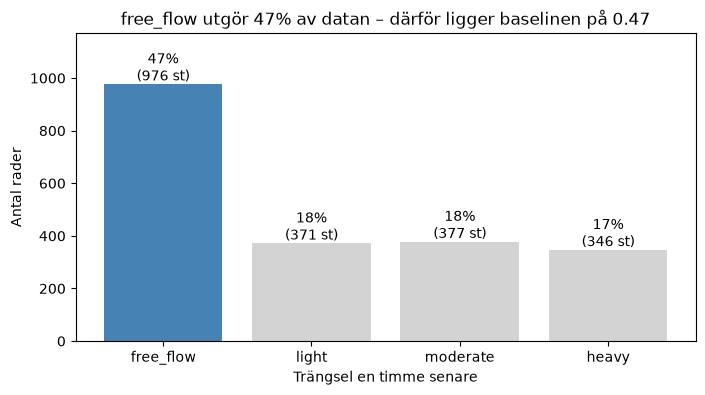

In [37]:
import matplotlib.pyplot as plt

ordning = ["free_flow", "light", "moderate", "heavy"]
antal = df["future_congestion_level"].value_counts().reindex(ordning)
andel = antal / antal.sum()

colors = ["steelblue", "lightgray", "lightgray", "lightgray"]

plt.figure(figsize=(8, 4))
bars = plt.bar(ordning, antal, color=colors)

for bar, n, p in zip(bars, antal, andel):
    plt.text(bar.get_x() + bar.get_width() / 2, n + 15,
             f"{p:.0%}\n({n} st)", ha="center")

plt.title(f"free_flow utgör {andel['free_flow']:.0%} av datan – därför ligger baselinen på {andel['free_flow']:.2f}")
plt.ylabel("Antal rader")
plt.xlabel("Trängsel en timme senare")
plt.ylim(0, antal.max() * 1.2)
plt.savefig("klassfordelning.png", dpi=150, bbox_inches="tight")
plt.show()

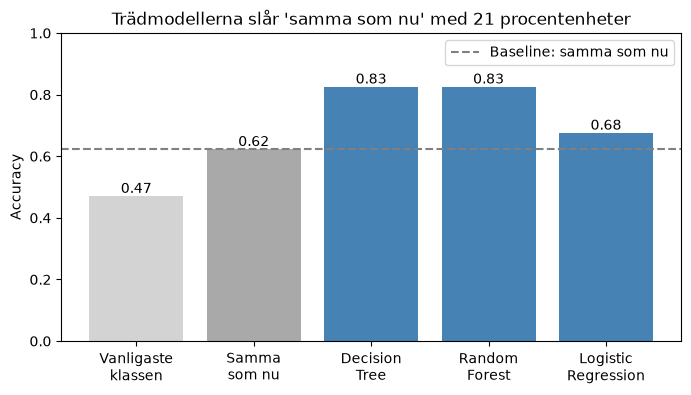

In [50]:
import matplotlib.pyplot as plt

# Samla resultaten
results = {
    "Vanligaste\nklassen": accuracy_score(y_test, dummy.predict(X_test)),
    "Samma\nsom nu": accuracy_score(y_test, samma_som_nu),
}
for name, m in models.items():
    results[name.replace(" ", "\n")] = accuracy_score(y_test, m.predict(X_test))

# Rita
names = list(results.keys())
values = list(results.values())
colors = ["lightgray", "darkgray", "steelblue", "steelblue", "steelblue"]

plt.figure(figsize=(8, 4))
bars = plt.bar(names, values, color=colors)
plt.axhline(values[1], linestyle="--", color="gray", label="Baseline: samma som nu")

for bar, v in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center")

plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Trädmodellerna slår 'samma som nu' med 21 procentenheter")
plt.legend()
plt.savefig("modeller_stapel.png", dpi=150, bbox_inches="tight")
plt.show()

Baseline: "samma som nu"
Vi använder mätningen från en viss tidpunkt (tid, temperatur, väder, vägtyp, hastighet, beläggning och trängseln just nu) för att förutsäga hur trängseln blir en timme senare.

Varför den här baselinen är viktig: trafik ändras oftast långsamt, så "samma som nu" är troligen en ganska bra gissning. En modell är bara värd något om den slår detta, alltså om den kan förutsäga förändringar och inte bara upprepa nuläget.

Slutsatsen: trädmodellerna kan verkligen förutsäga förändringar i trängseln, inte bara upprepa nuläget. De förstår till exempel att trafiken ökar när klockan närmar sig rusningstid.

Logistic Regression ligger nästan på baselinen. Det bekräftar samma sak som förut: trafik följer inte raka samband.

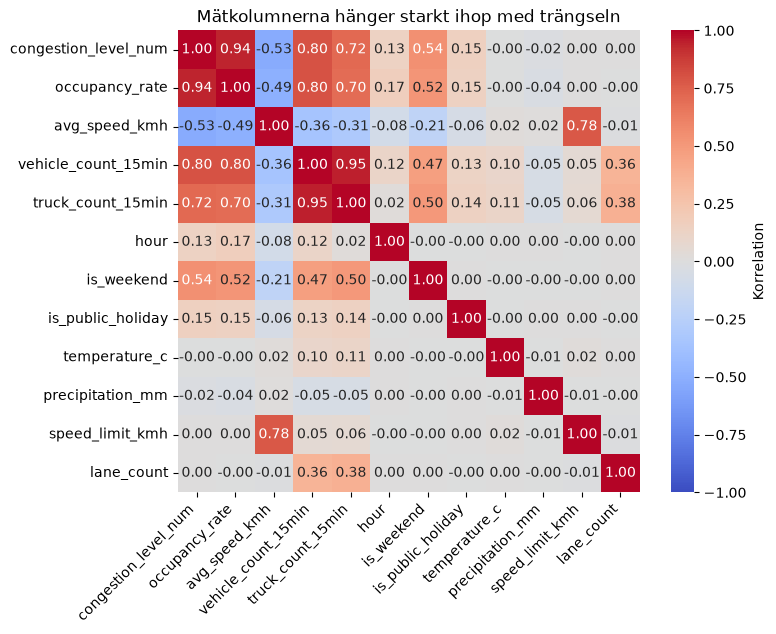

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

df_full = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "olaflundstrom/nordcauc-urban-mobility-intelligence",
    "traffic_flow_sensors.csv",
)
df_full = df_full[df_full["data_quality_flag"] == "good"]
# Gör om trängseln till siffror i ordning, bara för korrelationen
ordning = {"free_flow": 0, "light": 1, "moderate": 2, "heavy": 3}
data = df_full.copy()
data["congestion_level_num"] = data["congestion_level"].map(ordning)

# Välj numeriska kolumner (även True/False)
kolumner = [
    "congestion_level_num",
    "occupancy_rate", "avg_speed_kmh", "vehicle_count_15min", "truck_count_15min",
    "hour", "is_weekend", "is_public_holiday",
    "temperature_c", "precipitation_mm", "speed_limit_kmh", "lane_count",
]
corr = data[kolumner].astype(float).corr(method="spearman")

# Dölj den övre halvan (den är en spegelbild)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Korrelation"})
plt.title("Mätkolumnerna hänger starkt ihop med trängseln")
plt.xticks(rotation=45, ha="right")
plt.savefig("korrelation.png", dpi=150, bbox_inches="tight")
plt.show()

### Slutsats: korrelation

- **Mätkolumnerna hänger starkt ihop med trängseln:** `occupancy_rate` (0,94), `vehicle_count_15min` (0,80), `truck_count_15min` (0,72) och `avg_speed_kmh` (−0,53). Det bekräftar dataläckaget: när vi förutsäger trängseln *just nu* avslöjar de svaret, och därför togs de bort.
- **Väder och vägtyp har nästan inget samband** med trängseln (nära 0).
- **`hour` visar bara 0,13, men var ändå viktigast i modellen.** Korrelation mäter bara raka samband ("mer ger mer"). Trafiken går upp och ner under dygnet, ett mönster som korrelationen missar men som trädmodellerna hittar.
- **`is_weekend` är positiv (0,54),** alltså mer trängsel på helger. Det är tvärtom mot verklig trafik och tyder på att datasetet är syntetiskt.

Korrelation är ett bra första steg för att hitta läckage, men visar inte allt. Därför kompletterade vi med feature importance från modellerna.

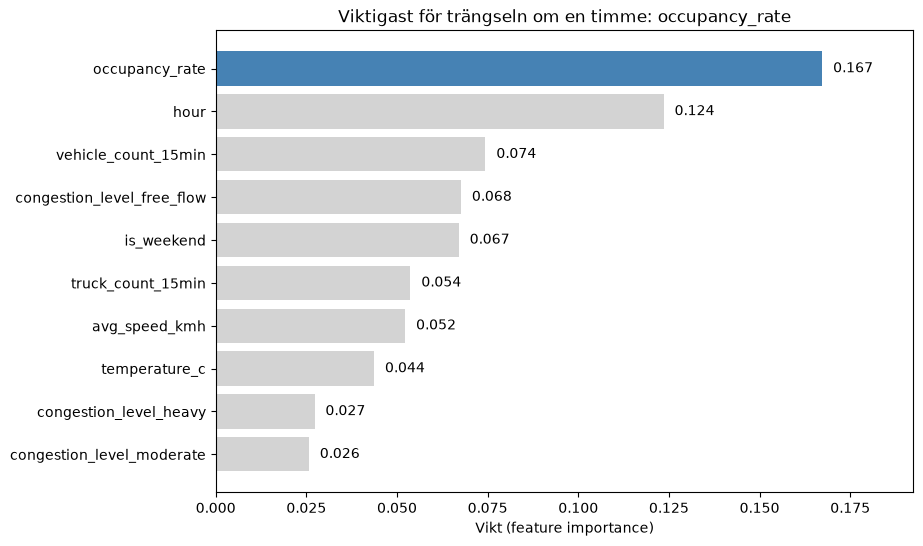

In [61]:
import matplotlib.pyplot as plt

rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=X.columns)
top10 = importance.sort_values(ascending=True).tail(10)

colors = ["lightgray"] * 9 + ["steelblue"]

plt.figure(figsize=(9, 6))
bars = plt.barh(top10.index, top10.values, color=colors)

for bar, v in zip(bars, top10.values):
    plt.text(v + 0.003, bar.get_y() + bar.get_height() / 2, f"{v:.3f}", va="center")

plt.title(f"Viktigast för trängseln om en timme: {top10.index[-1]}")
plt.xlabel("Vikt (feature importance)")
plt.xlim(0, top10.max() * 1.15)
plt.savefig("feature_importance_future.png", dpi=150, bbox_inches="tight")
plt.show()

För att förutsäga trängseln om en timme använder modellen främst hur full vägen är just nu, och vilken tid på dygnet det är. Tiden gör att modellen kan förutse förändringar, till exempel att trafiken ökar inför rusningstid. Det är därför den slår gissningen att det blir samma som nu.

Decision Tree : 0.787 ± 0.067
Random Forest : 0.807 ± 0.023
Logistic Regression : 0.551 ± 0.148


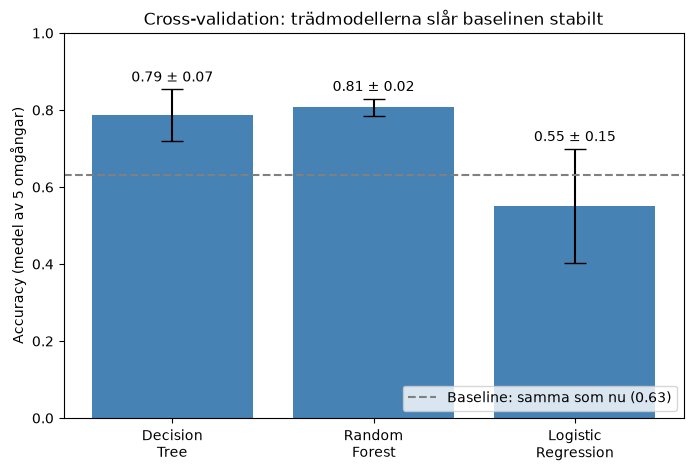

In [66]:
import matplotlib.pyplot as plt

namn = []
medel = []
spridning = []

for name, m in models.items():
    scores = cross_val_score(m, X, y, cv=5)
    namn.append(name.replace(" ", "\n"))
    medel.append(scores.mean())
    spridning.append(scores.std())
    print(name, ":", scores.mean().round(3), "±", scores.std().round(3))

# Baseline "samma som nu" på hela datan
baseline = accuracy_score(df["future_congestion_level"], df["congestion_level"])

plt.figure(figsize=(8, 5))
bars = plt.bar(namn, medel, yerr=spridning, capsize=8, color="steelblue")
plt.axhline(baseline, linestyle="--", color="gray", label=f"Baseline: samma som nu ({baseline:.2f})")

for bar, v, s in zip(bars, medel, spridning):
    plt.text(bar.get_x() + bar.get_width() / 2, v + s + 0.02,
             f"{v:.2f} ± {s:.2f}", ha="center")

plt.ylim(0, 1)
plt.ylabel("Accuracy (medel av 5 omgångar)")
plt.title("Cross-validation: trädmodellerna slår baselinen stabilt")
plt.legend(loc="lower right")
plt.savefig("cross_validation.png", dpi=150, bbox_inches="tight")
plt.show()

### Slutsats: cross-validation

- **Random Forest är bäst och mest stabil:** 0,81 ± 0,02. Resultatet varierar knappt mellan de fem omgångarna.
- **Decision Tree är nästan lika bra men mindre stabil:** 0,79 ± 0,07. Ett enda träd påverkas mer av vilken data
    det tränas på (risk för överanpassning).
- **Logistic Regression är sämre än baselinen:** 0,55 ± 0,15, under "samma som nu" (0,63).
    Trafikens upp-och-ned-mönster passar inte en linjär modell.

Vid en enda uppdelning fick Decision Tree och Random Forest samma accuracy (0,83). Cross-validation visar att
        **Random Forest är det säkrare valet**, eftersom den är lika bra men mycket stabilare. Vi går därför vidare med Random Forest.

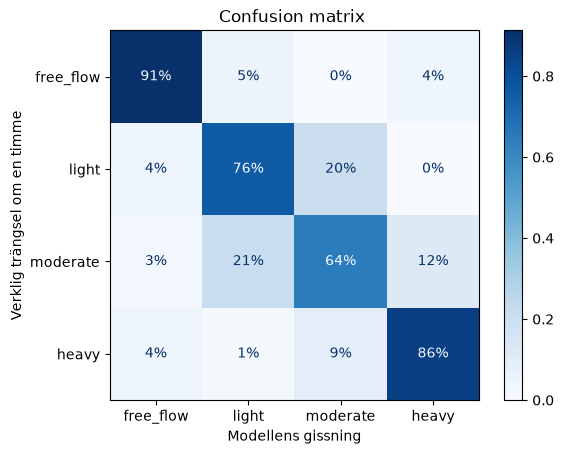

In [54]:
from sklearn.metrics import ConfusionMatrixDisplay

# Välj automatiskt modellen med högst accuracy
best_name = max(models, key=lambda n: accuracy_score(y_test, models[n].predict(X_test)))
best = models[best_name]

ordning = ["free_flow", "light", "moderate", "heavy"]

ConfusionMatrixDisplay.from_estimator(
    best, X_test, y_test,
    labels=ordning,
    normalize="true",
    values_format=".0%",
    cmap="Blues",
)
plt.title(f"Confusion matrix ")
plt.xlabel("Modellens gissning")
plt.ylabel("Verklig trängsel om en timme")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

diagonalen visar andelen rätt för varje klass. Rutorna bredvid diagonalen visar vilka klasser modellen blandar ihop
* Felen hamnar nästan alltid bredvid diagonalen, mellan grannklasser. Modellen gör alltså sällan grova misstag. Den har bara svårt att dra gränsen mellan närliggande nivåer, vilket är logiskt eftersom gränserna är otydliga. 

* En intressant detalj: 4 % free_flow gissades som heavy, och 4 % heavy gissades som free_flow. Det är “hopp” över hela skalan. De kan bero på plötsliga händelser, som en olycka (incident_type) eller början på rusningstid, som är svåra att förutse en timme i förväg.

För att förutsäga trängseln om en timme använder modellen främst hur full vägen är just nu, och vilken tid på 
dygnet det är. Tiden gör att modellen kan förutse förändringar, till exempel att trafiken ökar inför rusningstid.
    Det är därför den slår gissningen att det blir samma som nu.

In [64]:
# Ladda hela datan igen för att kunna gämföra graferna med varandra
df_full = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "olaflundstrom/nordcauc-urban-mobility-intelligence",
    "traffic_flow_sensors.csv",
)
df_full = df_full[df_full["data_quality_flag"] == "good"]

y_old = df_full["congestion_level"]
X_old = df_full.drop(columns=[
    "congestion_level",
    "occupancy_rate", "avg_speed_kmh", "vehicle_count_15min", "truck_count_15min",
    "sensor_id", "country", "district", "timestamp", "date",
    "latitude", "longitude", "ev_count_15min",
    "ai_predicted_volume", "ai_predicted_congestion", "ai_model_version",
    "data_quality_flag",
])
X_old = pd.get_dummies(X_old)

X_old_train, X_old_test, y_old_train, y_old_test = train_test_split(
    X_old, y_old, test_size=0.2, random_state=42, stratify=y_old
)
rf_old = RandomForestClassifier(random_state=42, n_jobs=-1).fit(X_old_train, y_old_train)
print("Gammal modell klar")

Gammal modell klar


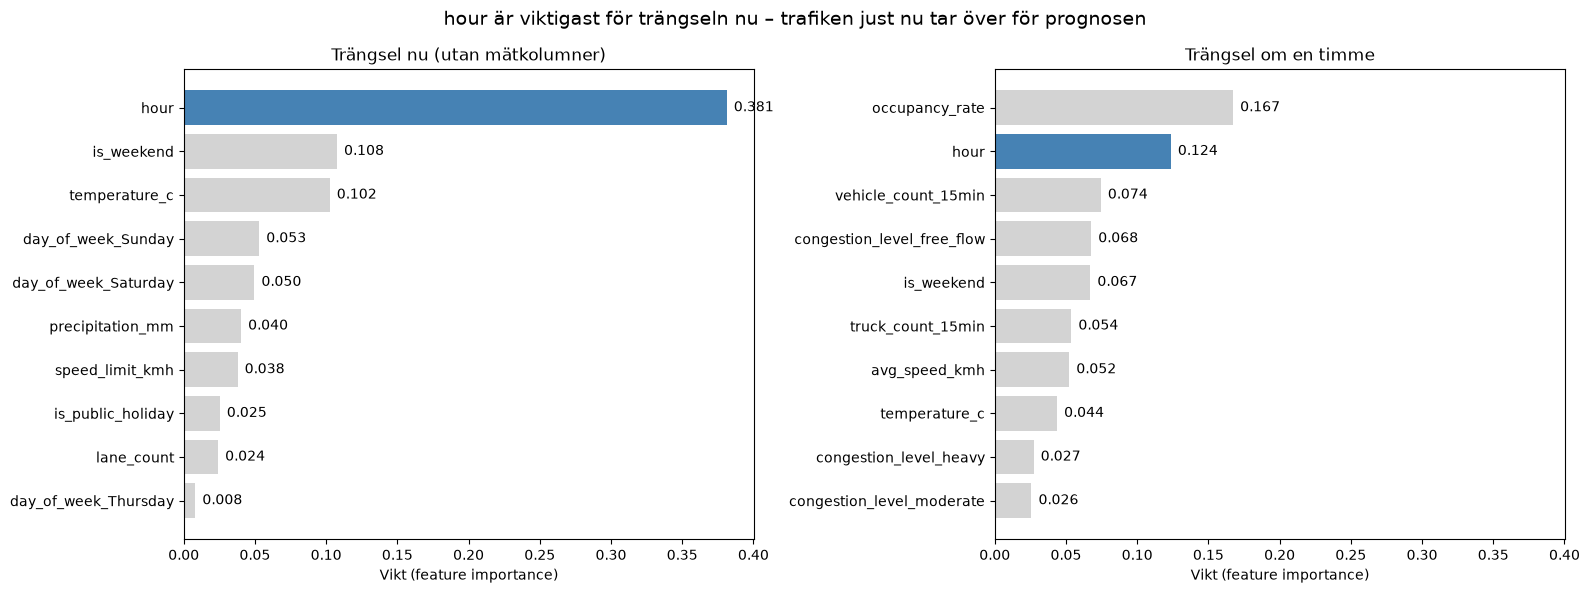

In [52]:
def rita(ax, model, kolumner, rubrik):
    imp = pd.Series(model.feature_importances_, index=kolumner)
    top10 = imp.sort_values(ascending=True).tail(10)
    colors = ["steelblue" if namn == "hour" else "lightgray" for namn in top10.index]
    bars = ax.barh(top10.index, top10.values, color=colors)
    for bar, v in zip(bars, top10.values):
        ax.text(v + 0.005, bar.get_y() + bar.get_height() / 2, f"{v:.3f}", va="center")
    ax.set_title(rubrik)
    ax.set_xlabel("Vikt (feature importance)")

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)

rita(axes[0], rf_old, X_old.columns, "Trängsel nu (utan mätkolumner)")
rita(axes[1], models["Random Forest"], X.columns, "Trängsel om en timme")

fig.suptitle("hour är viktigast för trängseln nu – trafiken just nu tar över för prognosen", fontsize=14)
plt.tight_layout()
plt.savefig("feature_importance_jamforelse.png", dpi=150, bbox_inches="tight")
plt.show()


När vi förutsäger trängseln just nu är tiden på dygnet viktigast. När vi förutsäger trängseln om en timme är det i stället trafiken just nu som väger tyngst, och tiden hjälper modellen att förutse förändringarna.

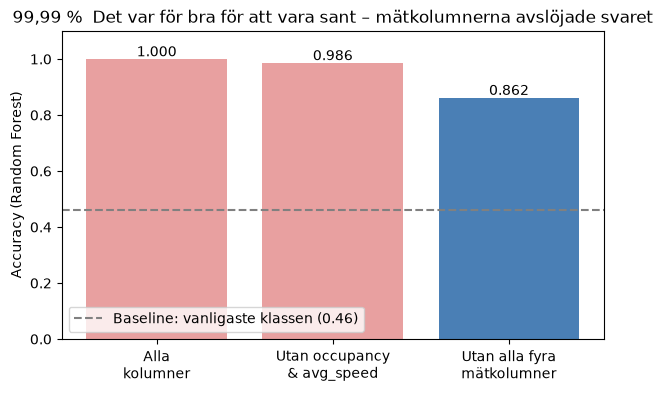

In [18]:
import matplotlib.pyplot as plt

steg = ["Alla\nkolumner", "Utan occupancy\n& avg_speed", "Utan alla fyra\nmätkolumner"]
accuracy = [0.9999, 0.986, 0.862]
colors = ["#E8A0A0", "#E8A0A0", "#4A7FB5"]

plt.figure(figsize=(7, 4))
bars = plt.bar(steg, accuracy, color=colors)
plt.axhline(0.462, linestyle="--", color="gray", label="Baseline: vanligaste klassen (0.46)")

for bar, v in zip(bars, accuracy):
    plt.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center")

plt.ylim(0, 1.1)
plt.ylabel("Accuracy (Random Forest)")
plt.title("99,99 %  Det var för bra för att vara sant – mätkolumnerna avslöjade svaret")
plt.legend(loc="lower left")
plt.savefig("dataläckage.png", dpi=120, bbox_inches="tight")
plt.show()

Ett för bra resultat är en varningssignal. Vi hittade och tog bort dataläckage.
Trädmodeller förutsäger trängseln om en timme med 83 % träffsäkerhet, 21 procentenheter bättre än att gissa “samma som nu”.
Modellen kombinerar trafiken just nu med tiden på dygnet för att förutse förändringar.